Импорт библиотек

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

настройки отображения

In [2]:
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)

Загрузка данных и выбор признаков

In [3]:
df = pd.read_csv('titanic.csv')

Выбираем нужные признаки + целевую переменную

In [4]:
features = ['Pclass', 'Age', 'Sex', 'Fare', 'SibSp', 'Parch']
target = 'Survived'

In [5]:
data = df[features + [target]].copy()
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,male,7.2500,1,0,0
1,1,38.0,female,71.2833,1,0,1
2,3,26.0,female,7.9250,0,0,1
3,1,35.0,female,53.1000,1,0,1
4,3,35.0,male,8.0500,0,0,0


Проверка пропусков

In [6]:
data.isnull().sum()

Pclass        0
Age         177
Sex           0
Fare          0
SibSp         0
Parch         0
Survived      0
dtype: int64

Обработка пропусков в Age

Заполняем медианой

In [7]:
data['Age'] = data['Age'].fillna(data['Age'].median())

data.isnull().sum()

Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64

Преобразование Sex в числовой вид

In [8]:
data['Sex'] = data['Sex'].map({'male': 0, 'female': 1})

In [9]:
data.head()

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
0,3,22.0,0,7.2500,1,0,0
1,1,38.0,1,71.2833,1,0,1
2,3,26.0,1,7.9250,0,0,1
3,1,35.0,1,53.1000,1,0,1
4,3,35.0,0,8.0500,0,0,0


Контроль подготовки данных

In [10]:
print("Типы данных:")
print(data.dtypes)
print("\nПропуски:")
print(data.isnull().sum())
print("\nРазмер таблицы:", data.shape)

Типы данных:
Pclass        int64
Age         float64
Sex           int64
Fare        float64
SibSp         int64
Parch         int64
Survived      int64
dtype: object

Пропуски:
Pclass      0
Age         0
Sex         0
Fare        0
SibSp       0
Parch       0
Survived    0
dtype: int64

Размер таблицы: (891, 7)


Корреляционная матрица

In [11]:
corr_matrix = data.corr()
corr_matrix.round(2)

,Pclass,Age,Sex,Fare,SibSp,Parch,Survived
Pclass,1.00,-0.34,-0.13,-0.55,0.08,0.02,-0.34
Age,-0.34,1.00,-0.08,0.10,-0.23,-0.17,-0.06
Sex,-0.13,-0.08,1.00,0.18,0.11,0.25,0.54
Fare,-0.55,0.10,0.18,1.00,0.16,0.22,0.26
SibSp,0.08,-0.23,0.11,0.16,1.00,0.41,-0.04
Parch,0.02,-0.17,0.25,0.22,0.41,1.00,0.08
Survived,-0.34,-0.06,0.54,0.26,-0.04,0.08,1.00


Анализ корреляции с Survived

In [12]:
corr_survived = corr_matrix['Survived'].drop('Survived') 
corr_survived_sorted = corr_survived.sort_values(ascending=False)
print(corr_survived_sorted.round(3))

print("\nНаиболее сильная положительная корреляция:")
print(corr_survived_sorted.idxmax(), "=", round(corr_survived_sorted.max(), 3))

print("\nНаиболее сильная отрицательная корреляция:")
print(corr_survived_sorted.idxmin(), "=", round(corr_survived_sorted.min(), 3))

Sex       0.543
Fare      0.257
Parch     0.082
SibSp    -0.035
Age      -0.065
Pclass   -0.338
Name: Survived, dtype: float64

Наиболее сильная положительная корреляция:
Sex = 0.543

Наиболее сильная отрицательная корреляция:
Pclass = -0.338


Тепловая карта

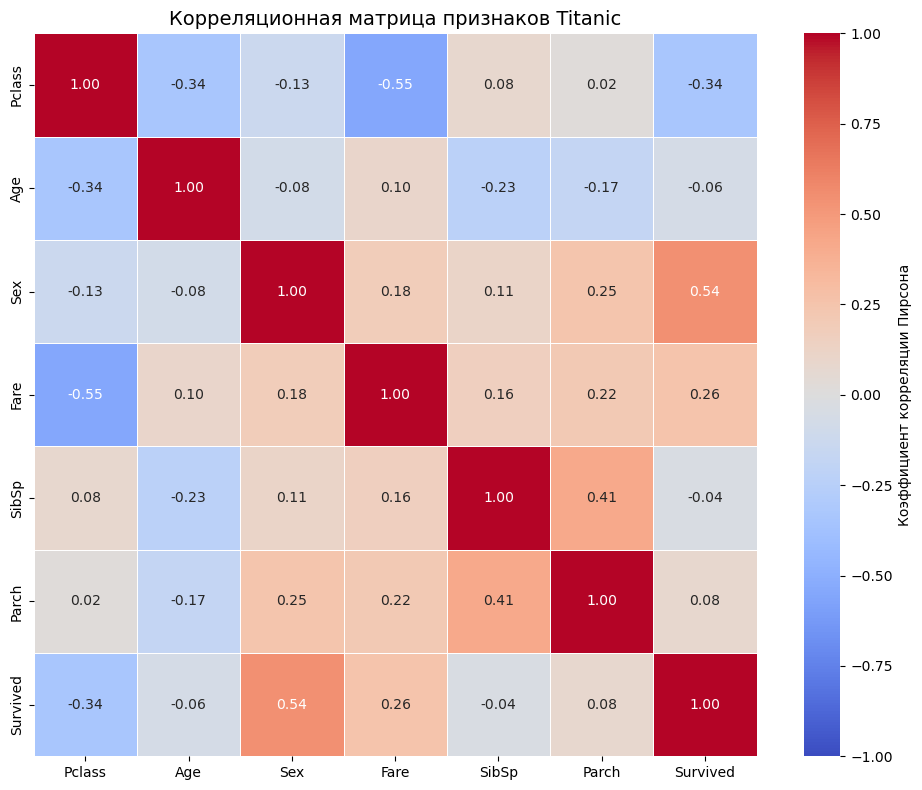

In [13]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,         
    fmt='.2f',          
    cmap='coolwarm',    
    vmin=-1, vmax=1,    
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Коэффициент корреляции Пирсона'}
)

plt.title('Корреляционная матрица признаков Titanic', fontsize=14)
plt.tight_layout()
plt.show()

Выводы

In [14]:
print("Рейтинг признаков по |corr| с Survived:")
print(corr_survived.abs().sort_values(ascending=False).round(3))

Рейтинг признаков по |corr| с Survived:
Sex       0.543
Pclass    0.338
Fare      0.257
Parch     0.082
Age       0.065
SibSp     0.035
Name: Survived, dtype: float64


Наиболее полезны для предсказания Survived:

Sex — сильнейшая связь (женщины выживали значительно чаще).

Pclass — сильная обратная связь (пассажиры 1-го класса выживали чаще).

Fare — умеренная положительная связь (коррелирует и с Pclass).

Age, SibSp, Parch — слабая линейная связь.

Можно ли выбирать признаки только по корреляции? — Нет. Причины:

Корреляция Пирсона улавливает только линейную связь; нелинейные зависимости (например, «дети и женщины спасались в первую очередь») могут не отразиться.

Корреляция не учитывает взаимодействие признаков (например, Sex + Pclass вместе дают больше, чем по отдельности).

Сильно коррелирующие между собой признаки (мультиколлинеарность, напр. Fare и Pclass) дублируют информацию — для модели это может быть избыточно.

Корреляция не доказывает причинность (об этом прямо сказано в теории).

Итоговый отбор признаков лучше делать по метрикам модели (feature importance, кросс-валидация), а корреляцию использовать как первичный ориентир.